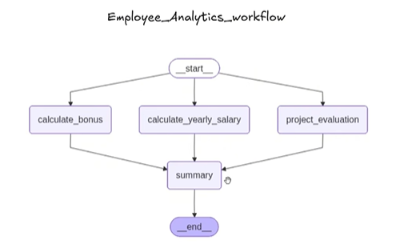

In [1]:
from dotenv import load_dotenv


In [2]:
load_dotenv()


True

In [3]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=1.0,
)

In [6]:
from langgraph.graph import StateGraph,START, END
from typing import TypedDict,Annotated

Define State

In [ ]:
class EmployeeState(TypedDict):
    employee_name:str
    monthly_salary:int
    working_days:int
    completed_projects:int
    yearly_salary:int
    bonus_amount:int
    project_status:int
    summary:str
    


Making functions for nodes

ONLY RETURN UPDATED STATE IN PARALLEL WORKFLOW

In [ ]:
def calculate_yearly_salary(state:EmployeeState):
    yearly_salary= state['monthly_salary']*12
    #update salary in state
    state['yearly_salary']=yearly_salary
    #return state  #do not return full state only return the value we are trying to update
    return {
        'yearly_salary':yearly_salary
    }


In [ ]:
def calculate_bonus(state:EmployeeState):
    bonus_amount= state['monthly_salary']*2
    #update salary in state
    return {
        'bonus_amount':bonus_amount
    }

In [ ]:
def project_evaluation(state:EmployeeState):
    #if completed projects>5 excellent else average
    if state['completed_projects']>5:
        status='Excellent'
    else:
        status='Average'

    return {
        'project_status':status
    }

In [ ]:
def summary(state:EmployeeState):
    summary_text=f"The employee has yearly salary of {state['yearly_salary']} with bonus amount of {state['bonus_amount']} and their project evaluation is {state['project_status']}"
    return {
        'summary':summary_text
    }

Creating Graph

In [ ]:
graph=StateGraph(EmployeeState)  #ab saari nodes ko employee ke parameters mil jaege

#make nodes
graph.add_node('calculate_yearly_salary',calculate_yearly_salary)

graph.add_node('calculate_bonus',calculate_bonus)

graph.add_node('project_evaluation',project_evaluation)

graph.add_node('summary',summary)

#add edges
graph.add_edge(START,'calculate_yearly_salary')
graph.add_edge(START,'calculate_bonus')
graph.add_edge(START,'project_evaluation')

graph.add_edge('calculate_yearly_salary','summary')
graph.add_edge('calculate_bonus','summary')
graph.add_edge('project_evaluation','summary')


graph.add_edge('summary',END)

#compile workflow
workflow=graph.compile()

In notebook we do not need to print graph explicitly. Just print workflow

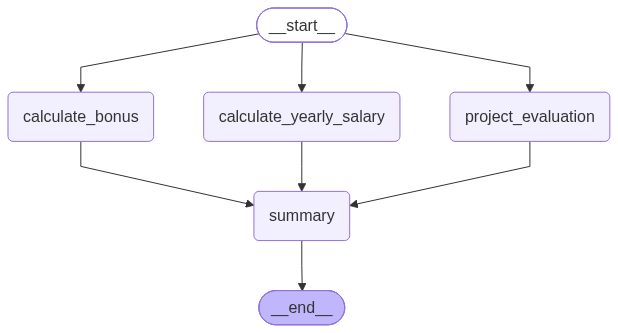

In [ ]:
workflow

execute workflow

In [ ]:
initial_state={
    "employee_name":"Ashutosh",
    "monthly_salary":28000,
    "working_days":22,
    "completed_projects":5
}

run workflow

In [ ]:
result=workflow.invoke(initial_state)

In [ ]:
print(result)

{'employee_name': 'Ashutosh', 'monthly_salary': 28000, 'working_days': 22, 'completed_projects': 5, 'yearly_salary': 336000, 'bonus_amount': 56000, 'project_status': 'Average', 'summary': 'The employee has yearly salary of 336000 with bonus amount of 56000 and their project evaluation is Average'}


LLM BASED PARALLEL WORKFLOW

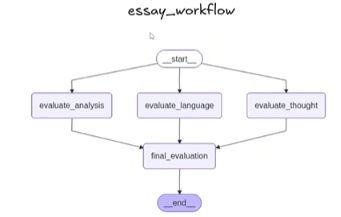

In [31]:
class EssayState(TypedDict):
    essay:str
    language_feedback:str
    analysis_feedback:str
    clarity_feedback:str
    overall_feedback:str
    individual_scores:Annotated[list[int],operator.add] #we need to sum each feedback. since har node se ek score aaega so we need a list
    avg_score:float

In [32]:
from pydantic import BaseModel,Field
import operator

In [33]:
class EvaluationSchema(BaseModel):
    feedback:str=Field(description='Detailed Feedback for essay')
    score:int=Field(description='Score out of 10',ge=0,le=10)

In [34]:
structured_model=model.with_structured_output(EvaluationSchema)  #ab har baar model will give feedback and score

In [35]:
essay="""
The Importance of Discipline

Discipline is one of the most important qualities for achieving success in life. It helps a person stay focused, manage time, and complete tasks consistently. A disciplined student, for example, studies regularly instead of waiting until the last moment. Discipline does not mean being perfect; it means following good habits even when motivation is low. With discipline, small efforts made every day can lead to significant results over time.
"""

In [36]:
prompt=f"Evaluate the provided essay on langaugae and give a score out of 10 {essay}"
result=structured_model.invoke(prompt)

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


In [37]:
print(result)

feedback='The essay is well-written, clear, and concise. It effectively introduces the topic of discipline, provides a relevant example of a student, and explains the core concept that discipline is about habits rather than perfection. The flow and grammar are excellent, though the essay is a bit short.' score=9


In [38]:
result.feedback

'The essay is well-written, clear, and concise. It effectively introduces the topic of discipline, provides a relevant example of a student, and explains the core concept that discipline is about habits rather than perfection. The flow and grammar are excellent, though the essay is a bit short.'

In [39]:
result.score

9

Making Functions for Nodes

In [40]:
def evaluate_language(state: EssayState):

    prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'language_feedback': output.feedback, 'individual_scores': [output.score]}

In [41]:
def evaluate_analysis(state: EssayState):

    prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'analysis_feedback': output.feedback, 'individual_scores': [output.score]}

In [42]:
def evaluate_thought(state: EssayState):

    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output = structured_model.invoke(prompt)

    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}

In [43]:
def final_evaluation(state: EssayState):

    # summary feedback
    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'
    overall_feedback = model.invoke(prompt).content

    # avg calculate
    avg_score = sum(state['individual_scores'])/len(state['individual_scores'])

    return {'overall_feedback': overall_feedback, 'avg_score': avg_score}

Making Graph

In [44]:
graph = StateGraph(EssayState)

# add nodes
graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('final_evaluation', final_evaluation)

# add edges
graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought')


graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_thought', 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow = graph.compile()

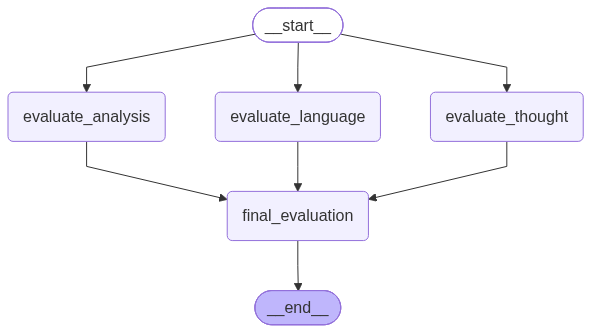

In [45]:
workflow

In [46]:
essay2 = """The United States in the Age of AI: The Infrastructure and Capital Superpower

As the world navigates the maturing landscape of artificial intelligence in 2026, the United States stands as the undisputed epicenter of the AI revolution. Driven by an ecosystem of hyperscalers, massive venture capital, and a fiercely competitive free market, the US has transitioned AI from a phase of speculative experimentation into the fundamental backbone of its digital and physical economy. However, the American approach to AI is no longer just a story of software and algorithms; it has evolved into the most capital-intensive infrastructure buildout in modern history, testing the physical limits of the nation's energy grid and resources.

The defining characteristic of the US AI strategy is its sheer scale and rapid commercialization. Silicon Valley and major tech hubs have pioneered the shift toward "Agentic AI" and "Physical AI." Intelligence is no longer confined to chatbots on a screen; autonomous agents are now orchestrating complex, end-to-end enterprise workflows, while advanced robotics powered by massive neural networks are redefining logistics and manufacturing floors. For American corporations, the current era marks a structural reorganization where operating models are being fundamentally redesigned around human-machine collaboration rather than merely automating legacy processes.

Yet, this relentless pursuit of scale has collided with physical reality, triggering an unprecedented energy reckoning. The US is building massive AI data center clusters that require gigawatts of continuous power. With data center electricity consumption projected to more than double in a span of just a few years, the nation is facing a severe power bottleneck. Connecting to the traditional grid now takes years, prompting hyperscalers to pioneer a "Bring Your Own Power" (BYOP) movement. Tech giants are directly funding behind-the-meter gas generation, reviving dormant nuclear facilities, and investing in advanced cooling technologies to fuel their server farms. AI infrastructure has become such a critical priority that it is increasingly viewed through the lens of national security, prompting aggressive federal action to expand the domestic supply of key electrical grid components.

On the policy front, the US government has dramatically accelerated its embrace of artificial intelligence. Moving away from more cautious regulatory frameworks, the focus has shifted entirely to removing barriers to innovation and ensuring tech sovereignty. The goal is clear: maintain a decisive strategic edge over global competitors, particularly China. Federal AI spending has skyrocketed into the tens of billions, dominated overwhelmingly by the Department of Defense, which views AI supremacy as a non-negotiable imperative for future military readiness, cybersecurity, and global diplomacy.

However, this hyper-accelerated growth is not without domestic friction. At the local level, the proliferation of massive data centers is creating tension in communities grappling with the environmental footprint of these facilities. Concerns over local electricity rate hikes, immense water usage in water-stressed regions, and the strain on existing utilities highlight the localized costs of a global tech race. Furthermore, while the US excels at rapid technological deployment, the corporate sector is experiencing a deep divide between companies effectively restructuring for an AI-native future and those struggling with high failure rates due to poor data quality and broken processes.

In conclusion, the United States in the age of AI represents a high-stakes, capital-fueled engine of exponential growth. It is a nation betting that its unmatched capacity for private investment, hardware innovation, and sheer ambition can overcome formidable physical bottlenecks. The American trajectory will ultimately determine whether a market-driven society can build and sustain the colossal physical infrastructure required to unlock the next frontier of human intelligence."""

In [47]:
intial_state = {
    'essay': essay2
}

result = workflow.invoke(intial_state)

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash

In [48]:
result

{'essay': 'The United States in the Age of AI: The Infrastructure and Capital Superpower\n\nAs the world navigates the maturing landscape of artificial intelligence in 2026, the United States stands as the undisputed epicenter of the AI revolution. Driven by an ecosystem of hyperscalers, massive venture capital, and a fiercely competitive free market, the US has transitioned AI from a phase of speculative experimentation into the fundamental backbone of its digital and physical economy. However, the American approach to AI is no longer just a story of software and algorithms; it has evolved into the most capital-intensive infrastructure buildout in modern history, testing the physical limits of the nation\'s energy grid and resources.\n\nThe defining characteristic of the US AI strategy is its sheer scale and rapid commercialization. Silicon Valley and major tech hubs have pioneered the shift toward "Agentic AI" and "Physical AI." Intelligence is no longer confined to chatbots on a scr